# 共享单车下一小时需求预测：阶段一
本阶段完成数据质量检查和训练集 EDA，模型将在后续加入。预测下一小时，不使用目标小时的实测天气。
请在 VS Code 选择 d2l 内核，从头运行全部单元。

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
assert (ROOT / 'src').exists(), '请从项目根目录或 notebooks 目录运行'
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.data import download, load_hourly, audit
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print(sys.executable)
config = json.loads((ROOT / 'configs/experiment.json').read_text(encoding='utf-8'))
download()
df = load_hourly()

D:\P Miniconda3.13\envs\d2l\python.exe


## 数据审计
全量数据仅用于结构与时间完整性检查；不查看最终测试集的目标分布来调参。

In [2]:
report = audit(df)
display({k: v for k, v in report.items() if k != 'missing_timestamps'})
print('缺失时刻示例:', report['missing_timestamps'][:10])
train = df.loc[df.index < config['train_end_exclusive']].copy()
print('EDA 只使用训练区间:', train.index.min(), train.index.max(), '样本数:', len(train))
display(train.describe())

{'rows': 17379,
 'start': '2011-01-01 00:00:00',
 'end': '2012-12-31 23:00:00',
 'expected_hours': 17544,
 'missing_hours': 165,
 'duplicate_timestamps': 0,
 'null_counts': {'instant': 0,
  'dteday': 0,
  'season': 0,
  'yr': 0,
  'mnth': 0,
  'hr': 0,
  'holiday': 0,
  'weekday': 0,
  'workingday': 0,
  'weathersit': 0,
  'temp': 0,
  'atemp': 0,
  'hum': 0,
  'windspeed': 0,
  'casual': 0,
  'registered': 0,
  'cnt': 0},
 'negative_counts': 0,
 'target_sum_mismatch': 0}

缺失时刻示例: ['2011-01-02 05:00:00', '2011-01-03 02:00:00', '2011-01-03 03:00:00', '2011-01-04 03:00:00', '2011-01-05 03:00:00', '2011-01-06 03:00:00', '2011-01-07 03:00:00', '2011-01-11 03:00:00', '2011-01-11 04:00:00', '2011-01-12 03:00:00']
EDA 只使用训练区间: 2011-01-01 00:00:00 2011-12-31 23:00:00 样本数: 8645


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,8645.000000,8645.000000,8645.0,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000,8645.00000,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000
mean,4323.000000,2.513592,0.0,6.573973,11.573626,0.027646,3.012724,0.683748,1.437594,0.489069,0.46900,0.643430,0.191172,28.600578,115.193869,143.794448
std,2495.740872,1.105477,0.0,3.428147,6.907822,0.163966,2.006370,0.465040,0.653859,0.197943,0.17676,0.196293,0.123191,38.840789,109.461014,133.797854
min,1.000000,1.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2162.000000,2.000000,0.0,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.320000,0.31820,0.490000,0.104500,3.000000,26.000000,31.000000
50%,4323.000000,3.000000,0.0,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.48480,0.650000,0.194000,14.000000,90.000000,109.000000
75%,6484.000000,3.000000,0.0,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.62120,0.810000,0.283600,38.000000,168.000000,211.000000
max,8645.000000,4.000000,0.0,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,0.960000,1.00000,1.000000,0.850700,272.000000,567.000000,651.000000


## 训练集可视化
图中是相关关系而不是因果结论。天气与节假日分组必须结合样本量解释。温度等字段为数据集归一化值。

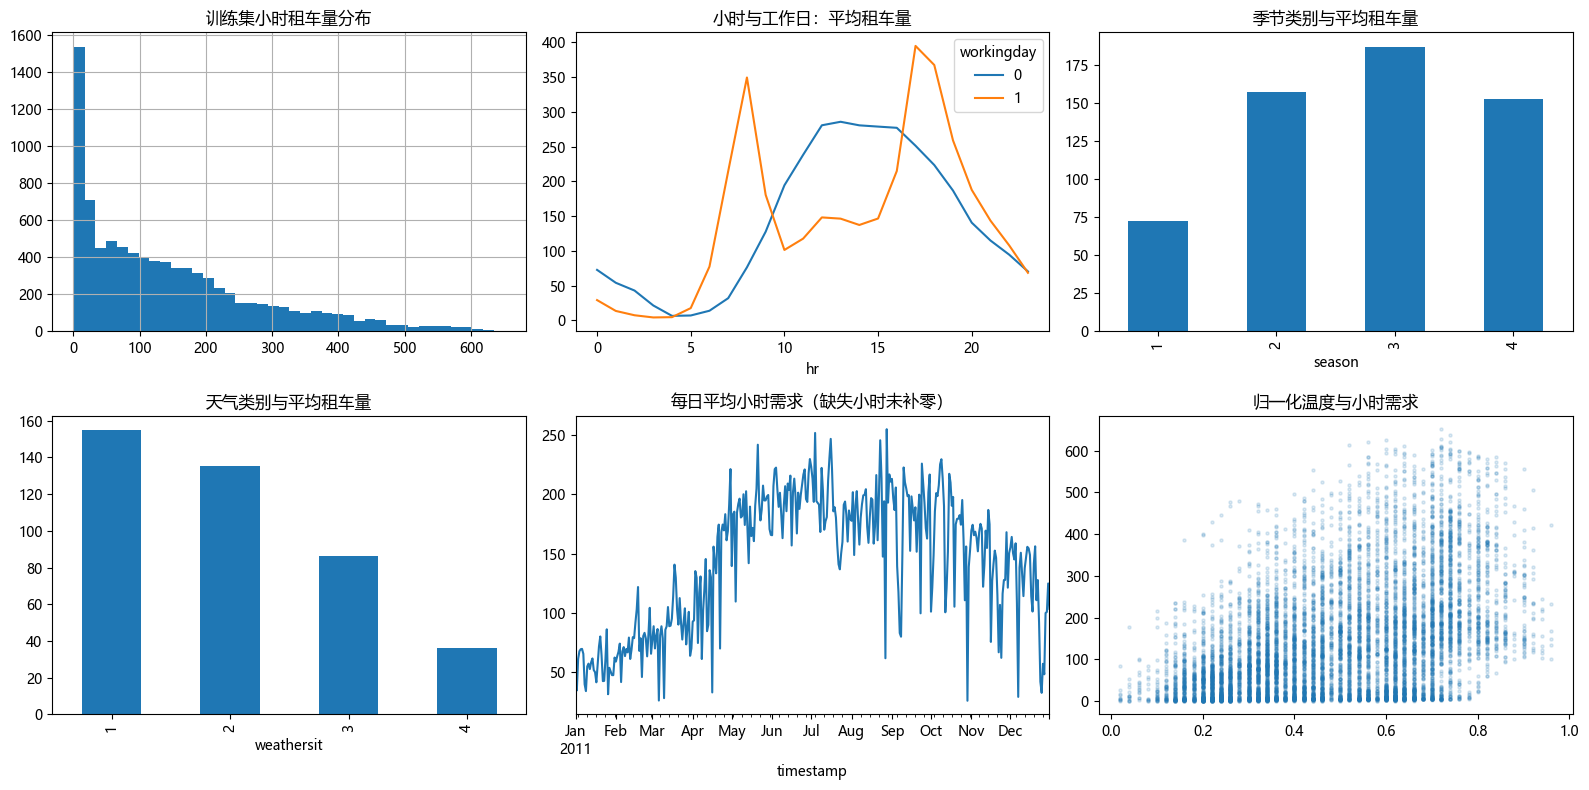

,count,mean,median
weathersit,,,
1,5645,155.013818,122.0
2,2218,135.490983,106.0
3,781,86.421255,50.0
4,1,36.000000,36.0


,count,mean,median
holiday,,,
0,8406,144.311325,110.0
1,239,125.615063,81.0


,count,mean,median
workingday,,,
0,2734,141.491953,93.0
1,5911,144.859415,115.0


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
train['cnt'].hist(bins=40, ax=axes[0, 0]); axes[0, 0].set_title('训练集小时租车量分布')
train.groupby(['hr', 'workingday'])['cnt'].mean().unstack().plot(ax=axes[0, 1]); axes[0, 1].set_title('小时与工作日：平均租车量')
train.groupby('season')['cnt'].mean().plot.bar(ax=axes[0, 2]); axes[0, 2].set_title('季节类别与平均租车量')
train.groupby('weathersit')['cnt'].mean().plot.bar(ax=axes[1, 0]); axes[1, 0].set_title('天气类别与平均租车量')
train.resample('D')['cnt'].mean().plot(ax=axes[1, 1]); axes[1, 1].set_title('每日平均小时需求（缺失小时未补零）')
axes[1, 2].scatter(train['temp'], train['cnt'], alpha=0.15, s=5); axes[1, 2].set_title('归一化温度与小时需求')
fig.tight_layout()
figures = ROOT / 'results/figures'; figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / 'training_eda.png', dpi=150, bbox_inches='tight')
plt.show()
for column in ['weathersit', 'holiday', 'workingday']:
    display(train.groupby(column)['cnt'].agg(['count', 'mean', 'median']))

## 后续实验约定
训练集：2011 年；验证集：2012 年上半年；最终测试：2012 年下半年。测试前固定滚动验证配置。
缺失小时不能当成零需求；后续在完整小时轴上构造滞后与 168 小时历史窗口，并使用训练数据拟合历史特征插补规则。
尚未训练模型，不报告预测指标，也不预设 LSTM 优于传统模型。